# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using Artificial Neural Networks to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

# Expected business outcomes

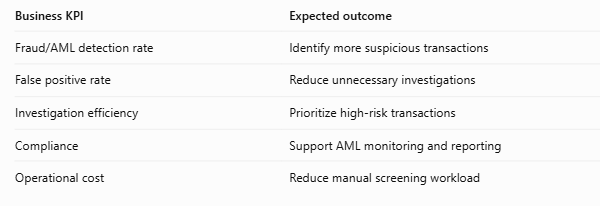

# Constraints

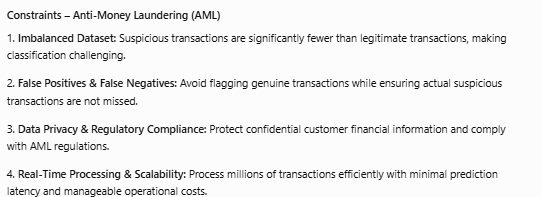

### Data understanding

#### Data collection

In [1]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [1]:
import kagglehub

In [2]:
link=r'berkanoztas/synthetic-transaction-monitoring-dataset-aml'
kagglehub.dataset_download(link,output_dir=r'A:\ANN')

'A:\\ANN'

#### Data Description

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
df=pd.read_csv(r'A:\ANN\SAML-D.csv')

In [5]:
df.shape

(9504852, 12)

In [6]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


Outputs=Is_laundering,Laundering_type  

inputs=Time,Date,Sender_account,Receiver_account,Amount,Payment_currency, Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type

In [7]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


### Data Preparation

#### Exploratory Data Analysis

#### Univariate Analysis

In [10]:
df.isna().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


In [13]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [14]:
df['Amount'].describe()

count    9.504852e+06
mean     8.762968e+03
std      2.561495e+04
min      3.730000e+00
25%      2.143688e+03
50%      6.113720e+03
75%      1.045846e+04
max      1.261850e+07
Name: Amount, dtype: float64

In [15]:
df['Payment_currency'].unique()

array(['UK pounds', 'Indian rupee', 'Albanian lek', 'Swiss franc',
       'Pakistani rupee', 'Naira', 'Yen', 'Euro', 'Dirham',
       'Mexican Peso', 'Turkish lira', 'US dollar', 'Moroccan dirham'],
      dtype=object)

In [16]:
df['Payment_currency'].value_counts(normalize=True)

Payment_currency
UK pounds          0.957331
Euro               0.012327
Turkish lira       0.002945
Swiss franc        0.002892
Dirham             0.002868
Pakistani rupee    0.002861
Naira              0.002856
US dollar          0.002742
Yen                0.002689
Moroccan dirham    0.002672
Mexican Peso       0.002615
Albanian lek       0.002607
Indian rupee       0.002594
Name: proportion, dtype: float64

In [17]:
df['Received_currency'].value_counts(normalize=True)

Received_currency
UK pounds          0.924123
Euro               0.024399
Pakistani rupee    0.004839
Yen                0.004820
Moroccan dirham    0.004813
Albanian lek       0.004812
Mexican Peso       0.004761
Naira              0.004739
Indian rupee       0.004604
US dollar          0.004594
Swiss franc        0.004517
Dirham             0.004503
Turkish lira       0.004476
Name: proportion, dtype: float64

In [18]:
df['Sender_bank_location'].value_counts(normalize=True)

Sender_bank_location
UK             0.966147
Turkey         0.002199
Switzerland    0.002157
Pakistan       0.002141
UAE            0.002113
Nigeria        0.002107
Spain          0.002040
Germany        0.002026
USA            0.002002
Italy          0.001988
France         0.001968
Japan          0.001943
Morocco        0.001940
Austria        0.001899
Mexico         0.001858
Albania        0.001857
India          0.001851
Netherlands    0.001764
Name: proportion, dtype: float64

In [19]:
df['Receiver_bank_location'].value_counts(normalize=True)

Receiver_bank_location
UK             0.932643
Pakistan       0.004101
Austria        0.004087
Albania        0.004080
Japan          0.004075
Morocco        0.004072
Germany        0.004055
France         0.004052
Mexico         0.004038
Nigeria        0.004027
Netherlands    0.003926
Spain          0.003923
India          0.003886
USA            0.003877
Italy          0.003842
Switzerland    0.003796
UAE            0.003777
Turkey         0.003744
Name: proportion, dtype: float64

<Axes: ylabel='count'>

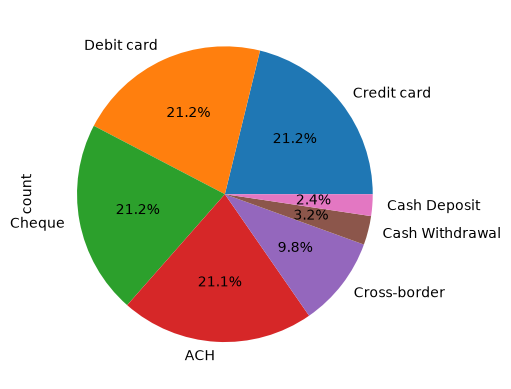

In [20]:
df['Payment_type'].value_counts().plot(kind='pie',autopct='%.1f%%')

<Axes: xlabel='Is_laundering'>

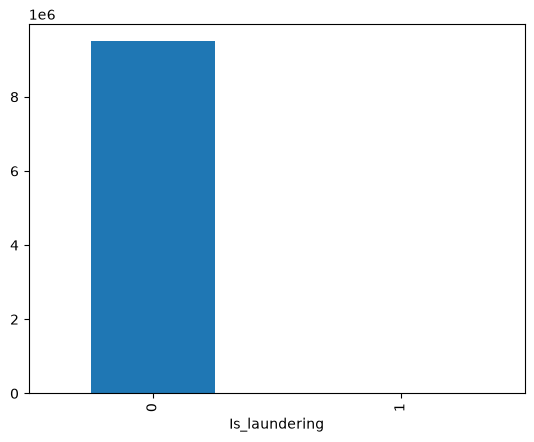

In [21]:
df['Is_laundering'].value_counts().plot(kind='bar')

<Axes: xlabel='Laundering_type'>

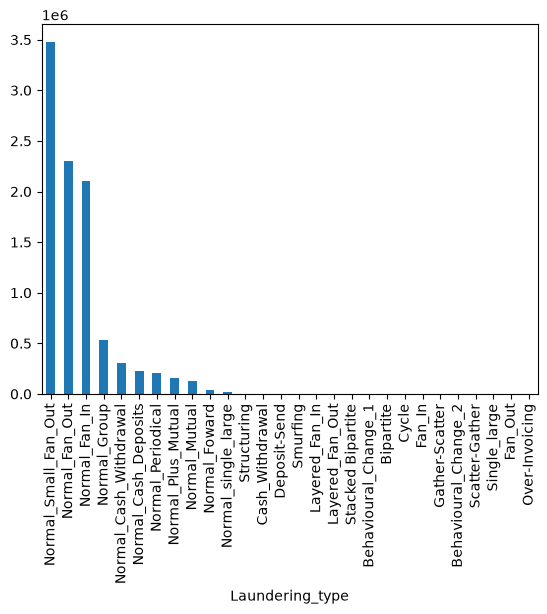

In [22]:
df['Laundering_type'].value_counts().plot(kind='bar')

<Axes: xlabel='Laundering_type'>

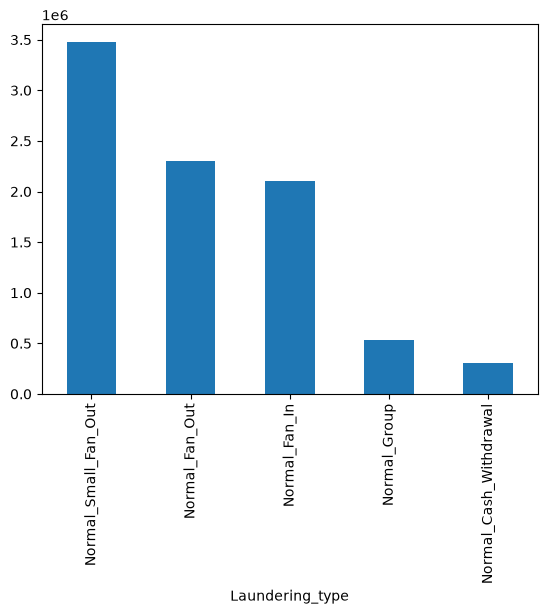

In [23]:
df['Laundering_type'].value_counts().nlargest(5).plot(kind='bar')

#### Bivariate Analysis

In [24]:
#categorical vs categorical

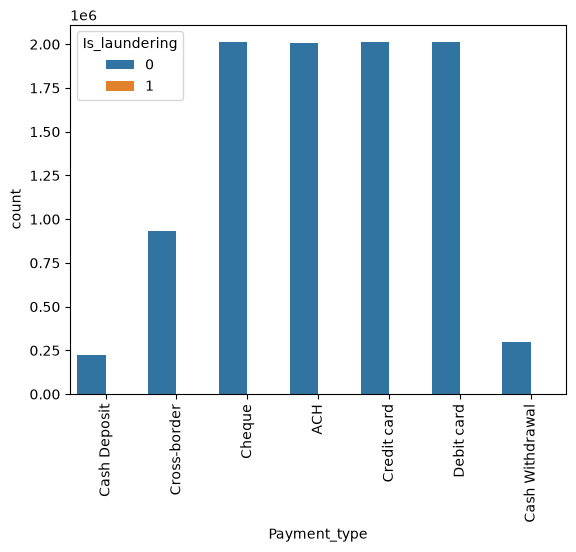

In [25]:
sns.countplot(x=df['Payment_type'],hue=df['Is_laundering'])
plt.xticks(rotation=90)
plt.show()

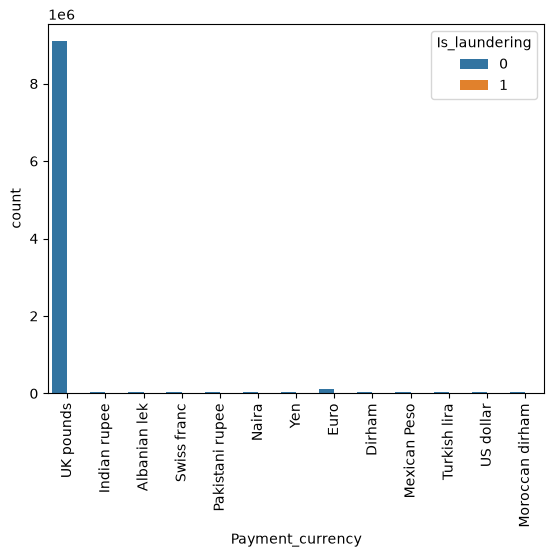

In [26]:
sns.countplot(x=df['Payment_currency'],hue=df['Is_laundering'])
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='Is_laundering', ylabel='Amount'>

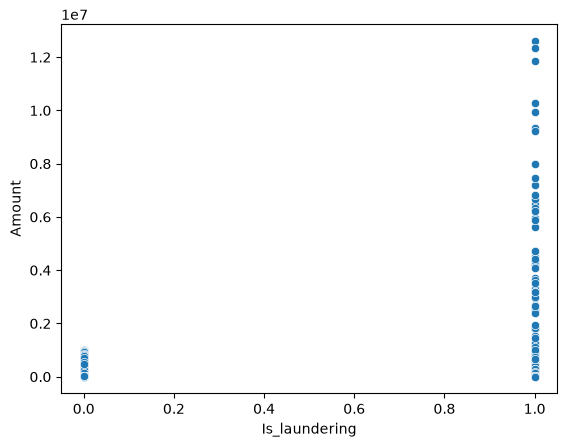

In [27]:
sns.scatterplot(x=df['Is_laundering'],y=df['Amount'])


#### Data Cleaning

In [28]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [8]:
df['Sender_account']=df['Sender_account'].astype('str')
df['Receiver_account']=df['Receiver_account'].astype('str')

In [9]:
df['Date']=df['Date'].astype('datetime64[ns]')

In [10]:
df['Date'].dt.year

0          2022
1          2022
2          2022
3          2022
4          2022
           ... 
9504847    2023
9504848    2023
9504849    2023
9504850    2023
9504851    2023
Name: Date, Length: 9504852, dtype: int32

In [11]:
df.drop(columns=['Time','Date','Laundering_type','Sender_account','Receiver_account'],inplace=True)

In [12]:
df=df.sample(n=100000,random_state=23)

In [13]:
df.shape

(100000, 7)

In [14]:
X=df.drop(columns=['Is_laundering'])
y=df['Is_laundering']

In [15]:
X.columns

Index(['Amount', 'Payment_currency', 'Received_currency',
       'Sender_bank_location', 'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [19]:
X['Payment_type'].unique()

array(['Cash Withdrawal', 'ACH', 'Cash Deposit', 'Cheque', 'Debit card',
       'Cross-border', 'Credit card'], dtype=object)

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [21]:
# Categorical columns
cat_columns = X.select_dtypes(include=['object']).columns

# Numerical columns
numerical_cols = X.select_dtypes(exclude=['object']).columns

In [22]:
cat_columns

Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [23]:
numerical_cols

Index(['Amount'], dtype='object')

In [24]:
cat_transformer=Pipeline([('OHE',OneHotEncoder(dtype='int'))])

In [25]:
numerical_transformer=Pipeline([('Scaling',StandardScaler())])

In [26]:
preprocess=ColumnTransformer([('cat_transformer',cat_transformer,cat_columns),
                  ('numerical_transformer',numerical_transformer,numerical_cols)])

In [27]:
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat_transformer', ...), ('numerical_transformer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transform

In [28]:
from imblearn.over_sampling import SMOTE

In [29]:
resampling=Pipeline([('Preprocessing',preprocess),
         ('SMOTE',SMOTE(random_state=23))])

In [30]:
resampling

,steps,"[('Preprocessing', ...), ('SMOTE', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat_transformer', ...), ('numerical_transformer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be 

In [31]:
X_s,y_s=resampling.fit_resample(X,y)

#### Model Building

In [32]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,BatchNormalization,Dropout


In [33]:
model=Sequential()

model.add(Input(shape=(X_s.shape[1],)))

model.add(Dense(units=16,activation='relu'))
model.add(Dense(units=8,activation='relu'))
model.add(Dense(units=4,activation='relu'))
model.add(Dense(units=2,activation='relu'))

model.add(Dense(units=1,activation='sigmoid'))


In [34]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [35]:
history=model.fit(X_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step - accuracy: 0.7848 - loss: 0.4727 - val_accuracy: 0.6349 - val_loss: 0.6361
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 23s 5ms/step - accuracy: 0.8048 - loss: 0.4083 - val_accuracy: 0.5887 - val_loss: 0.6491
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 26s 5ms/step - accuracy: 0.8070 - loss: 0.3989 - val_accuracy: 0.5766 - val_loss: 0.5901
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.8084 - loss: 0.3946 - val_accuracy: 0.6328 - val_loss: 0.5402
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.8102 - loss: 0.3910 - val_accuracy: 0.6288 - val_loss: 0.5740
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.8107 - loss: 0.3883 - val_accuracy: 0.6451 - val_loss: 0.5293
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.8111 - loss: 0.3862 - val_accuracy: 0.6083 - val_loss: 0.5308
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.8124 - loss: 0

In [36]:
epochs=range(1,31)
train_loss=history.history['loss']
val_loss=history.history['val_loss']

#### Hyperparameter Tuning

In [37]:
import optuna
from tensorflow.keras.optimizers import Adam,RMSprop,SGD
from tensorflow.keras.callbacks import EarlyStopping

In [47]:

def objective(trial):

    # Search Space
    n_layers = trial.suggest_int('n_layers', 1, 4)

    learning_rate = trial.suggest_float(
        'learning_rate', 0.0001, 0.1, log=True
    )

    batch_size = trial.suggest_categorical(
        'batch_size', [16, 32, 64, 128, 256]
    )

    optimizer_name = trial.suggest_categorical(
        'optimizer', ['adam', 'rmsprop', 'sgd']
    )

    # Building the model
    model = Sequential()

    model.add(Input(shape=(X_s.shape[1],)))

    for i in range(n_layers):

        units = trial.suggest_int(f'units_layer_{i}', 2, 32)

        dropout_rate = trial.suggest_float(
            f'dropout_layer_{i}', 0.0, 0.6
        )

        activation = trial.suggest_categorical(
            f'activation_{i}', ['relu', 'tanh', 'sigmoid']
        )

        model.add(Dense(units=units, activation=activation))

        model.add(Dropout(rate=dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    # Optimizer
    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)

    elif optimizer_name == 'rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate)

    else:
        optimizer = SGD(learning_rate=learning_rate)

    # Compile
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Early stopping
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Training
    history = model.fit(
        X_s,
        y_s,
        validation_split=0.2,
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stop]
    )

    best_loss = min(history.history['val_loss'])

    trial.set_user_attr('best_val_loss', float(best_loss))

    return best_loss


In [48]:
study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler())

[I 2026-11-11 13:09:02,412] A new study created in memory with name: no-name-950bb92d-a5ea-499e-b92a-ca50f88ad073


In [49]:
study.optimize(objective,n_trials=3)

Epoch 1/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.7372 - loss: 0.5524 - val_accuracy: 0.5763 - val_loss: 0.7986
Epoch 2/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.7655 - loss: 0.5094 - val_accuracy: 0.5919 - val_loss: 0.6635
Epoch 3/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.7751 - loss: 0.4885 - val_accuracy: 0.5791 - val_loss: 0.6893
Epoch 4/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.7806 - loss: 0.4765 - val_accuracy: 0.5961 - val_loss: 0.6397
Epoch 5/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.7844 - loss: 0.4670 - val_accuracy: 0.5383 - val_loss: 0.7311
Epoch 6/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.7861 - loss: 0.4637 - val_accuracy: 0.5316 - val_loss: 0.7806
Epoch 7/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.7876 - loss: 0.4588 - val_accuracy: 0.5478 - val_loss: 0.6726
Epoch 8/100
9989/9989 ━━━━━━━━━━━━━━━━━━━━ 25s 2ms/step - accuracy: 0.7878 -

[I 2026-11-11 13:15:15,101] Trial 0 finished with value: 0.503972053527832 and parameters: {'n_layers': 3, 'learning_rate': 0.041215895947376444, 'batch_size': 16, 'optimizer': 'sgd', 'units_layer_0': 26, 'dropout_layer_0': 0.21847669374568585, 'activation_0': 'relu', 'units_layer_1': 8, 'dropout_layer_1': 0.42418577680748415, 'activation_1': 'tanh', 'units_layer_2': 22, 'dropout_layer_2': 0.5839935694587601, 'activation_2': 'relu'}. Best is trial 0 with value: 0.503972053527832.


Epoch 1/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6242 - loss: 0.6628 - val_accuracy: 0.0000e+00 - val_loss: 0.9281
Epoch 2/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6250 - loss: 0.6585 - val_accuracy: 0.0000e+00 - val_loss: 0.8330
Epoch 3/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6276 - loss: 0.6476 - val_accuracy: 0.7452 - val_loss: 0.6681
Epoch 4/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6659 - loss: 0.6228 - val_accuracy: 0.9648 - val_loss: 0.5996
Epoch 5/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.7020 - loss: 0.5981 - val_accuracy: 1.0000 - val_loss: 0.4882
Epoch 6/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.7225 - loss: 0.5784 - val_accuracy: 1.0000 - val_loss: 0.4286
Epoch 7/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.7381 - loss: 0.5622 - val_accuracy: 1.0000 - val_loss: 0.3914
Epoch 8/100
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 

[I 2026-11-11 13:19:53,527] Trial 1 finished with value: 0.2802000045776367 and parameters: {'n_layers': 4, 'learning_rate': 0.026912452989178076, 'batch_size': 32, 'optimizer': 'sgd', 'units_layer_0': 9, 'dropout_layer_0': 0.37390286065092504, 'activation_0': 'sigmoid', 'units_layer_1': 23, 'dropout_layer_1': 0.46406547643177304, 'activation_1': 'relu', 'units_layer_2': 14, 'dropout_layer_2': 0.3736180123419681, 'activation_2': 'tanh', 'units_layer_3': 21, 'dropout_layer_3': 0.04973686211702453, 'activation_3': 'relu'}. Best is trial 1 with value: 0.2802000045776367.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7195 - loss: 0.5786 - val_accuracy: 0.5479 - val_loss: 0.7486
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7651 - loss: 0.5192 - val_accuracy: 0.5817 - val_loss: 0.7075
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7757 - loss: 0.5043 - val_accuracy: 0.5881 - val_loss: 0.7249
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7801 - loss: 0.4980 - val_accuracy: 0.5944 - val_loss: 0.6939
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7809 - loss: 0.4940 - val_accuracy: 0.5877 - val_loss: 0.7280
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7825 - loss: 0.4856 - val_accuracy: 0.6029 - val_loss: 0.6491
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7844 - loss: 0.4748 - val_accuracy: 0.6009 - val_loss: 0.6482
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7862 - loss: 0

[I 2026-11-11 13:21:50,960] Trial 2 finished with value: 0.6015289425849915 and parameters: {'n_layers': 2, 'learning_rate': 0.0003704659654308079, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer_0': 4, 'dropout_layer_0': 0.10421565523485485, 'activation_0': 'relu', 'units_layer_1': 32, 'dropout_layer_1': 0.14931743049912627, 'activation_1': 'relu'}. Best is trial 1 with value: 0.2802000045776367.


In [41]:
model=Sequential()

model.add(Input(shape=(X_s.shape[1],)))

model.add(Dense(units=14,activation='relu'))
model.add(Dense(units=14,activation='relu'))

model.add(Dense(units=1,activation='sigmoid'))


In [42]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [43]:
history=model.fit(X_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.7780 - loss: 0.4843 - val_accuracy: 0.5509 - val_loss: 0.7771
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 19s 4ms/step - accuracy: 0.8006 - loss: 0.4217 - val_accuracy: 0.6110 - val_loss: 0.6016
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.8064 - loss: 0.3934 - val_accuracy: 0.6186 - val_loss: 0.5649
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 19s 4ms/step - accuracy: 0.8105 - loss: 0.3819 - val_accuracy: 0.6991 - val_loss: 0.5121
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - accuracy: 0.8119 - loss: 0.3756 - val_accuracy: 0.6541 - val_loss: 0.5920
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.8119 - loss: 0.3726 - val_accuracy: 0.7313 - val_loss: 0.4895
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.8134 - loss: 0.3703 - val_accuracy: 0.6699 - val_loss: 0.5231
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 29s 6ms/step - accuracy: 0.8144 - loss: 0

In [44]:
import pickle
import joblib

In [45]:
model.save('AML.keras')

In [46]:
joblib.dump(preprocess,'preprocessor')

['preprocessor']